In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

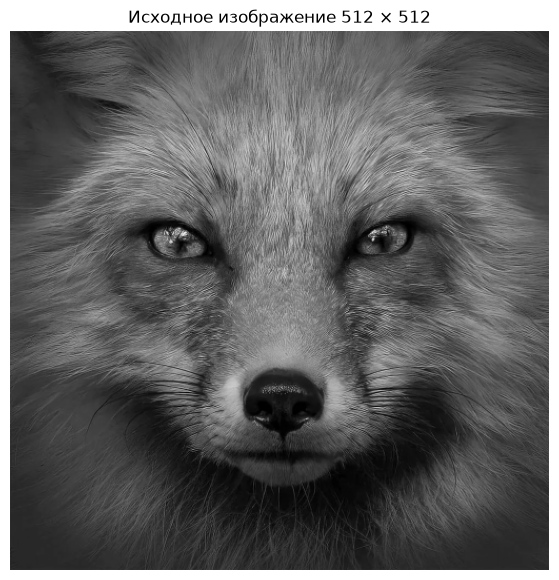

In [4]:
image_path = Path.home() / 'Desktop' / 'fox.jfif'

image = cv2.imread(str(image_path), cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError('Файл fox.jfif не найден на рабочем столе')

image = cv2.resize(image, (512, 512), interpolation=cv2.INTER_AREA)

plt.figure(figsize=(7, 7))
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение 512 × 512')
plt.axis('off')
plt.show()

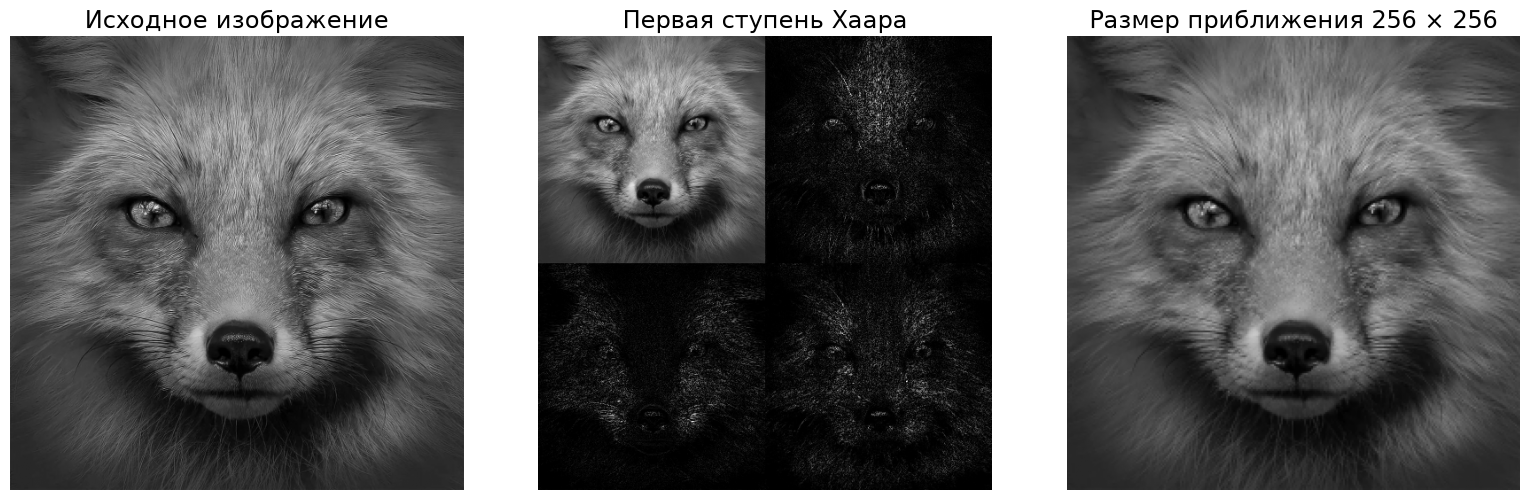

Исходный размер: (512, 512)
Первая ступень приближения: (256, 256)


In [14]:
def haar_step(img):
    h, w = img.shape
    data = img.astype(np.float32)

    temp = np.zeros((h, w), dtype=np.float32)

    temp[:, :w//2] = (
        data[:, 0::2] + data[:, 1::2]
    ) / np.sqrt(2)

    temp[:, w//2:] = (
        data[:, 0::2] - data[:, 1::2]
    ) / np.sqrt(2)

    result = np.zeros((h, w), dtype=np.float32)

    result[:h//2, :] = (
        temp[0::2, :] + temp[1::2, :]
    ) / np.sqrt(2)

    result[h//2:, :] = (
        temp[0::2, :] - temp[1::2, :]
    ) / np.sqrt(2)

    return result

haar_level1 = haar_step(image)

approx1 = haar_level1[:256, :256] / 2

haar_view1 = np.zeros((512, 512), dtype=np.float32)

haar_view1[:256, :256] = cv2.normalize(
    approx1, None, 0, 255, cv2.NORM_MINMAX
)

for y, x in [(0, 256), (256, 0), (256, 256)]:
    block = haar_level1[y:y+256, x:x+256]

    haar_view1[y:y+256, x:x+256] = cv2.normalize(
        np.abs(block), None, 0, 255, cv2.NORM_MINMAX
    )

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение', fontsize=17)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(haar_view1, cmap='gray', vmin=0, vmax=255)
plt.title('Первая ступень Хаара', fontsize=17)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(approx1, cmap='gray', vmin=0, vmax=255)
plt.title('Размер приближения 256 × 256', fontsize=17)
plt.axis('off')

plt.tight_layout()
plt.show()

print('Исходный размер:', image.shape)
print('Первая ступень приближения:', approx1.shape)


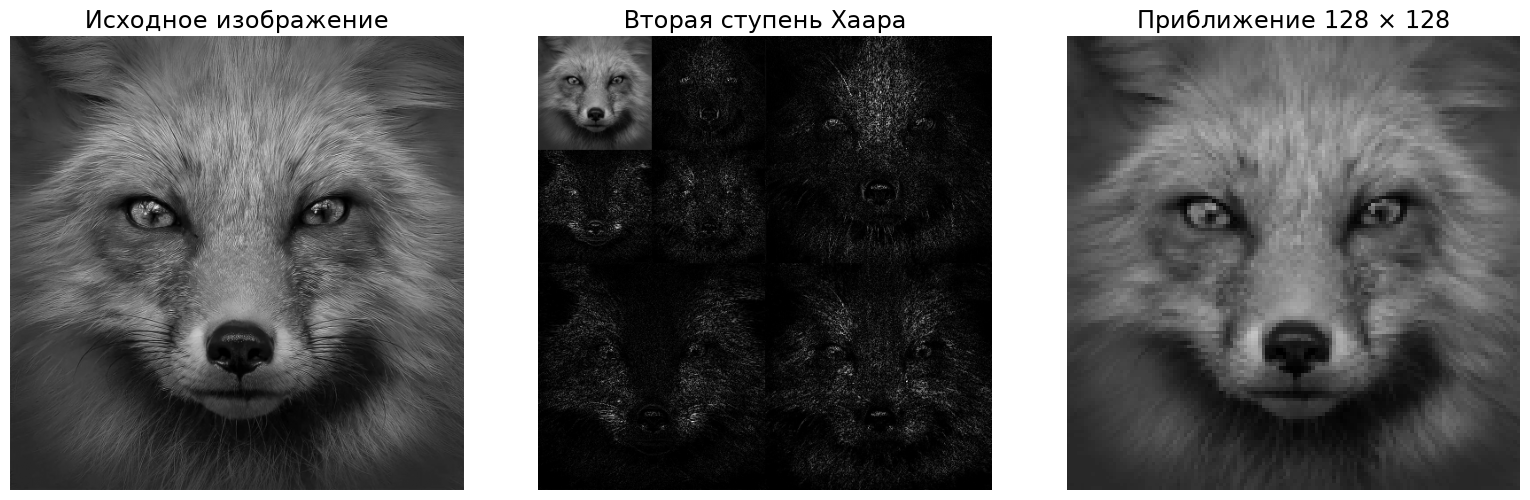

Исходный размер: (512, 512)
Вторая ступень приближения: (128, 128)


In [15]:
haar_level2 = haar_level1.copy()

haar_level2[:256, :256] = haar_step(
    haar_level1[:256, :256]
)

approx2 = haar_level2[:128, :128] / 4

haar_view2 = haar_view1.copy()
haar_view2[:128, :128] = np.clip(approx2, 0, 255)

for y, x in [(0, 128), (128, 0), (128, 128)]:
    block = haar_level2[y:y+128, x:x+128]

    haar_view2[y:y+128, x:x+128] = cv2.normalize(
        np.abs(block), None, 0, 255, cv2.NORM_MINMAX
    )

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение', fontsize=17)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(haar_view2, cmap='gray', vmin=0, vmax=255)
plt.title('Вторая ступень Хаара', fontsize=17)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(approx2, cmap='gray', vmin=0, vmax=255)
plt.title('Приближение 128 × 128', fontsize=17)
plt.axis('off')

plt.tight_layout()
plt.show()

print('Исходный размер:', image.shape)
print('Вторая ступень приближения:', approx2.shape)

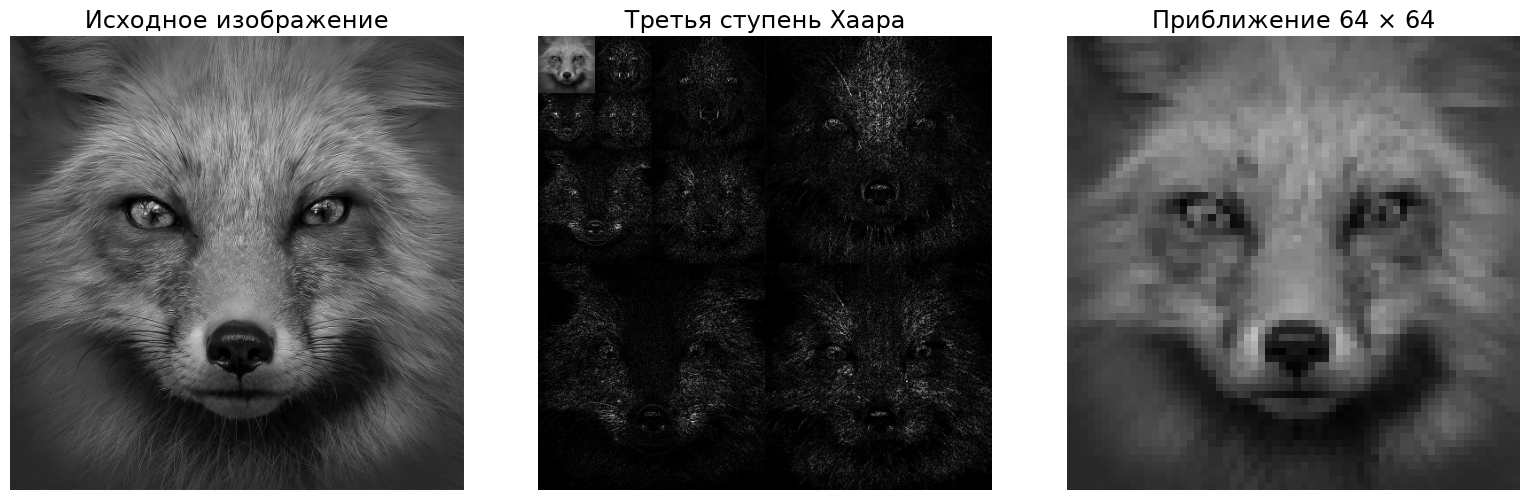

Исходный размер: (512, 512)
Третья ступень приближения (64, 64)


In [16]:
haar_level3 = haar_level2.copy()

haar_level3[:128, :128] = haar_step(
    haar_level2[:128, :128]
)

approx3 = haar_level3[:64, :64] / 8

haar_view3 = haar_view2.copy()
haar_view3[:64, :64] = np.clip(approx3, 0, 255)

for y, x in [(0, 64), (64, 0), (64, 64)]:
    block = haar_level3[y:y+64, x:x+64]

    haar_view3[y:y+64, x:x+64] = cv2.normalize(
        np.abs(block), None, 0, 255, cv2.NORM_MINMAX
    )

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray', vmin=0, vmax=255)
plt.title('Исходное изображение', fontsize=17)
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(haar_view3, cmap='gray', vmin=0, vmax=255)
plt.title('Третья ступень Хаара', fontsize=17)
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(approx3, cmap='gray', vmin=0, vmax=255)
plt.title('Приближение 64 × 64', fontsize=17)
plt.axis('off')

plt.tight_layout()
plt.show()

print('Исходный размер:', image.shape)
print('Третья ступень приближения', approx3.shape)

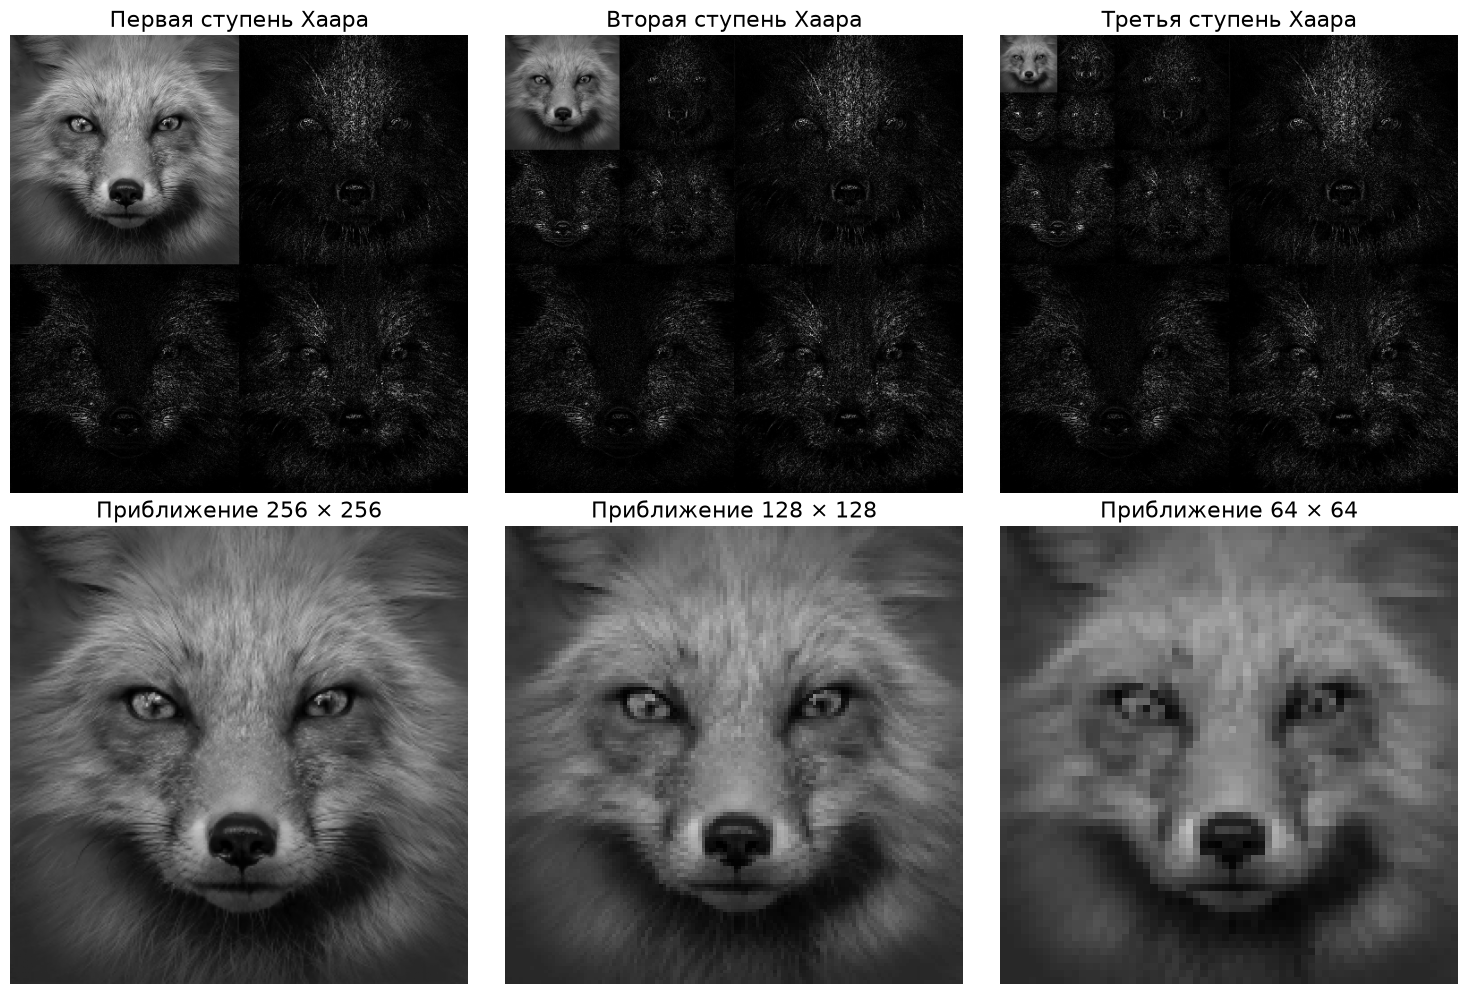

Вывод:
С каждой ступенью размер приближения уменьшается в 2 раза по ширине и высоте.
Постепенно теряются мелкие детали изображения, но основные черты лисы сохраняются.


In [19]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(haar_view1, cmap='gray', vmin=0, vmax=255)
plt.title('Первая ступень Хаара', fontsize=16)
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(haar_view2, cmap='gray', vmin=0, vmax=255)
plt.title('Вторая ступень Хаара', fontsize=16)
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(haar_view3, cmap='gray', vmin=0, vmax=255)
plt.title('Третья ступень Хаара', fontsize=16)
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(approx1, cmap='gray', vmin=0, vmax=255)
plt.title('Приближение 256 × 256', fontsize=16)
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(approx2, cmap='gray', vmin=0, vmax=255)
plt.title('Приближение 128 × 128', fontsize=16)
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(approx3, cmap='gray', vmin=0, vmax=255)
plt.title('Приближение 64 × 64', fontsize=16)
plt.axis('off')

plt.tight_layout()
plt.show()

print('Вывод:')
print('С каждой ступенью размер приближения уменьшается в 2 раза по ширине и высоте.')
print('Постепенно теряются мелкие детали изображения, но основные черты лисы сохраняются.')